# Part 1. The Basics

## 1. a. Setup and Imports

We'll install and import the packages we need.  
Run this cell once at the start.

In [ ]:
# If running on Google colab, uncomment and run the next line:
!pip install qiskit qiskit-aer matplotlib pylatexenc sympy "qiskit[visualization]" qiskit-ibm-runtime qiskit_qasm3_import numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 80.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 92.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 73.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 25.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 122.9/122.9 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.5 kB 16.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 113.3/113.3 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 59.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.2/234.2 kB 16.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 144.5/1

In [ ]:
from qiskit import QuantumCircuit
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram, plot_bloch_multivector

from qiskit_aer import AerSimulator

from qiskit_ibm_runtime import SamplerV2 as Sampler, EstimatorV2 as Estimator, QiskitRuntimeService

## 1. b. Qubits and Basic Gates

A **qubit** starts in the state $\lvert 0\rangle=\begin{bmatrix}1\\0\end{bmatrix}$; It's other measureable state is  $\lvert 1\rangle=\begin{bmatrix}0\\1\end{bmatrix}$.


We apply quantum **gates** (unitary operations) to change its state.

We'll demonstrate:
- `X` gate (like a NOT: flips |0⟩ ↔ |1⟩)  
- `H` gate (Hadamard: creates superposition)  
- `Z` gate (phase flip)

In [ ]:
qc = QuantumCircuit(1, name="basic_gates_demo")
qc.x(0)      # Apply X (bit flip)
qc.h(0)      # Put qubit in superposition
qc.z(0)      # Add a phase flip
qc.draw('mpl')

## 1. c. Illustrations

We'll inspect the state after these gates using Qiskit's `Statevector` tools.

In [ ]:
# Get the statevector after the gates (without measurement)
state = Statevector.from_instruction(qc)
display(state)

NameError: name 'qc' is not defined

In [ ]:
state_vector = Statevector.from_instruction(qc)
state_vector.draw('latex')

$|\psi\rangle = \cos\left(\frac{\theta}{2}\right)|0\rangle + e^{i\phi}\sin\left(\frac{\theta}{2}\right)|1\rangle$

https://en.wikipedia.org/wiki/Bloch_sphere#/media/File:Bloch_sphere.svg


In [ ]:
# Plot on the Bloch sphere
plot_bloch_multivector(state)

## 1. d. Measurement and Histogram

When you **measure** a qubit, the quantum state collapses to classical 0 or 1.

We'll:
1. Create a superposition using `H`
2. Apply what we just learnt
3. Measure many times
4. Plot the frequency of results

In [ ]:
qc_meas = QuantumCircuit(1)
# TODO: Apply a Hadamard gate
qc_meas.draw('mpl')

In [ ]:
# TODO: Draw the statevector here

In [ ]:
# TODO: Generate the bloch sphere

In [ ]:
# qc_meas.measure_all()
qc_meas.measure(0,0)     # measure qubit -> classical bit
qc_meas.draw('mpl')

In [ ]:
# Use Qiskit's Aer simulator to sample measurement outcomes
backend = AerSimulator()
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_bell = pm.run(qc_meas)

sampler = Sampler(mode=backend) # remember, this is one of the primitives

job = sampler.run([isa_bell], shots=1024)
result = job.result()
counts = result[0].data.c.get_counts()

plot_histogram(counts, sort='value_desc')

## 1. e. Subcircuits / Modular Circuits

We can build reusable **subcircuits** (custom gates).  
Below, we'll define an `Entangle` block that:
1. Applies `H` on qubit 0  
2. Applies `Y` on qubit 1
2. Applies `X` on qubit 0
3. Applies `CX` (CNOT) from qubit 0 → qubit 1

Then we'll append it to a new circuit.

In [ ]:
# Define a 2-qubit subcircuit
sub = QuantumCircuit(2, name="Sub circuit 1")
# TODO: Apply the gates
# sub.draw('mpl')

In [ ]:
# Convert subcircuit to a Gate so we can reuse it
entangle_gate = sub.to_gate(label="My 'Entangle' Gate")

# Build a fresh circuit and append it
qc_modular = QuantumCircuit(2)
qc_modular.append(entangle_gate, [0,1])
qc_modular.draw('mpl')

## Example. Bell States and Entanglement

A **Bell state** is a 2-qubit entangled state.

The four Bell states (also known as EPR pairs) are:

- **Φ⁺**: $|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}$
  
- **Φ⁻**: $|\Phi^-\rangle = \frac{|00\rangle - |11\rangle}{\sqrt{2}}$
  
- **Ψ⁺**: $|\Psi^+\rangle = \frac{|01\rangle + |10\rangle}{\sqrt{2}}$
  
- **Ψ⁻**: $|\Psi^-\rangle = \frac{|01\rangle - |10\rangle}{\sqrt{2}}$

The Bell state $|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}$ is maximally entangled.

We can create this with:
1. Hadamard on qubit 0  
2. CNOT from qubit 0 to qubit 1

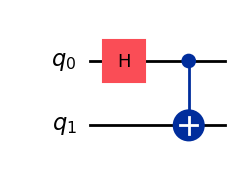

In [ ]:
bell_phi_plus = QuantumCircuit(2)
bell_phi_plus.h(0)
bell_phi_plus.cx(0,1)
bell_phi_plus.draw('mpl')

### View the Bell State (Statevector)

In [ ]:
bell_state_vector = Statevector.from_instruction(bell_phi_plus)
bell_state_vector.draw('latex')

### Measure the Bell State

We'll measure 2 qubits many times to see correlations.
We expect only `00` and `11` outcomes (high correlation).

In [ ]:
bell_meas = QuantumCircuit(2)
bell_meas.h(0)
bell_meas.cx(0,1)
# bell_meas.measure([0,1],[0,1])
bell_meas.measure_all()

backend = AerSimulator()
# Scalable way, if you want swap backends later on

# pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
# bell_result = pm.run(bell_meas)
# sampler = Sampler(mode=backend)
# job = sampler.run([bell_result], shots=1024)
# result = job.result()
# counts = result[0].data.c.get_counts()
# print("Bell State Counts:", counts)
# plot_histogram(counts)

# Old style of plotting, if you only want ot run on locals
job = backend.run(bell_meas, shots=1024)
result = job.result()
counts = result.get_counts()
print("Bell State Counts:", counts)
plot_histogram(counts)

### Puzzle 1: Let's work on psi minus (5 minutes)

- **Ψ⁻**: $|\Psi^-\rangle = \frac{|01\rangle - |10\rangle}{\sqrt{2}}$


In [ ]:
# TODO: Create PSI MINUS

bell_psi_minus = QuantumCircuit(2)
# Apply gates here
bell_psi_minus.draw('mpl')



In [ ]:
bell_state_vector = Statevector.from_instruction(bell_psi_minus)
bell_state_vector.draw('latex')

In [ ]:
# Measure before simulations
bell_psi_minus.measure_all()

In [ ]:
backend = AerSimulator()
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
bell_result = pm.run(bell_psi_minus)

sampler = Sampler(mode=backend)

job = backend.run(bell_result, shots=1024)
result = job.result()
counts = result.get_counts()

print("Bell State Counts:", counts)
plot_histogram(counts)


---

## Let's take a breather! 5 - 10 mins

---

## Part 2: Flow Control and Parameterization

### Dynamic circuits

##### The "simple", pythonic way

In [ ]:
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# Step 1: Create initial circuit
qc = QuantumCircuit(1, 1)
qc.x(0)
# qc.x(0)
qc.measure(0, 0)

qc.draw('mpl')


In [ ]:
# Step 2: Run the measurement
sim = AerSimulator()
qc_t = transpile(qc, sim)
job = sim.run(qc_t, shots=1)  # single shot to get one result
result = job.result()
counts = result.get_counts()

print("Measurement result:", counts)

# Extract the measured bit (either '0' or '1')
measured_bit = int(list(counts.keys())[0][0])  # first bitstring character
print("Measured bit:", measured_bit)

# Step 3: Build a new circuit that applies X if result == 1
qc2 = QuantumCircuit(1)
if measured_bit == 1:
    print("The CODE detected 1!")
    qc2.x(0)
else:
    qc2.z(0)

In [ ]:
qc2.draw('mpl')

#### if_test() context manager

**Explanation:** Qiskit supports dynamic circuits where operations can be conditioned on classical measurement outcomes. The `if_test()` context manager can be used to create conditional blocks where operations are executed based on classical bit values. This allows for powerful classical feed-forward in your quantum programs.

In [ ]:
qc = QuantumCircuit(2, 1)
qc.h(0)
qc.measure(0, 0)

with qc.if_test((qc.clbits[0], 1)):
    qc.x(1)

qc.draw('mpl')

### Parameterization

In [ ]:
from qiskit.circuit import Parameter, ParameterVector
import numpy as np

theta = Parameter('θ')
qc = QuantumCircuit(1)
qc.rx(theta, 0)

print('Original Unbound Circuit:')
display(qc.draw('mpl'))

bound_qc = qc.assign_parameters({theta: np.pi/2})

print('New Bound Circuit:')
bound_qc.draw('mpl')

# Part 3: Deutsch–Jozsa Algorithm
https://quantum.cloud.ibm.com/learning/en/modules/computer-science/deutsch-jozsa
https://www.cl.cam.ac.uk/teaching/1920/QuantComp/Quantum_Computing_Lecture_7.pdf

**Problem:**  
You're given a hidden Boolean function \( f(x) \) that maps n input bits → 1 output bit.  
You are promised that \( f \) is either:
- **constant**: returns the same value for every input, OR
- **balanced**: returns 0 for half the inputs and 1 for half.

**Goal:** Determine if \( f \) is constant or balanced,
using *one* quantum query vs. many classical queries.

We'll:
1. Build oracles (constant / balanced)
2. Build the Deutsch–Jozsa circuit
3. Simulate and read the answer

∣x⟩∣y⟩↦∣x⟩∣y⊕f(x)⟩

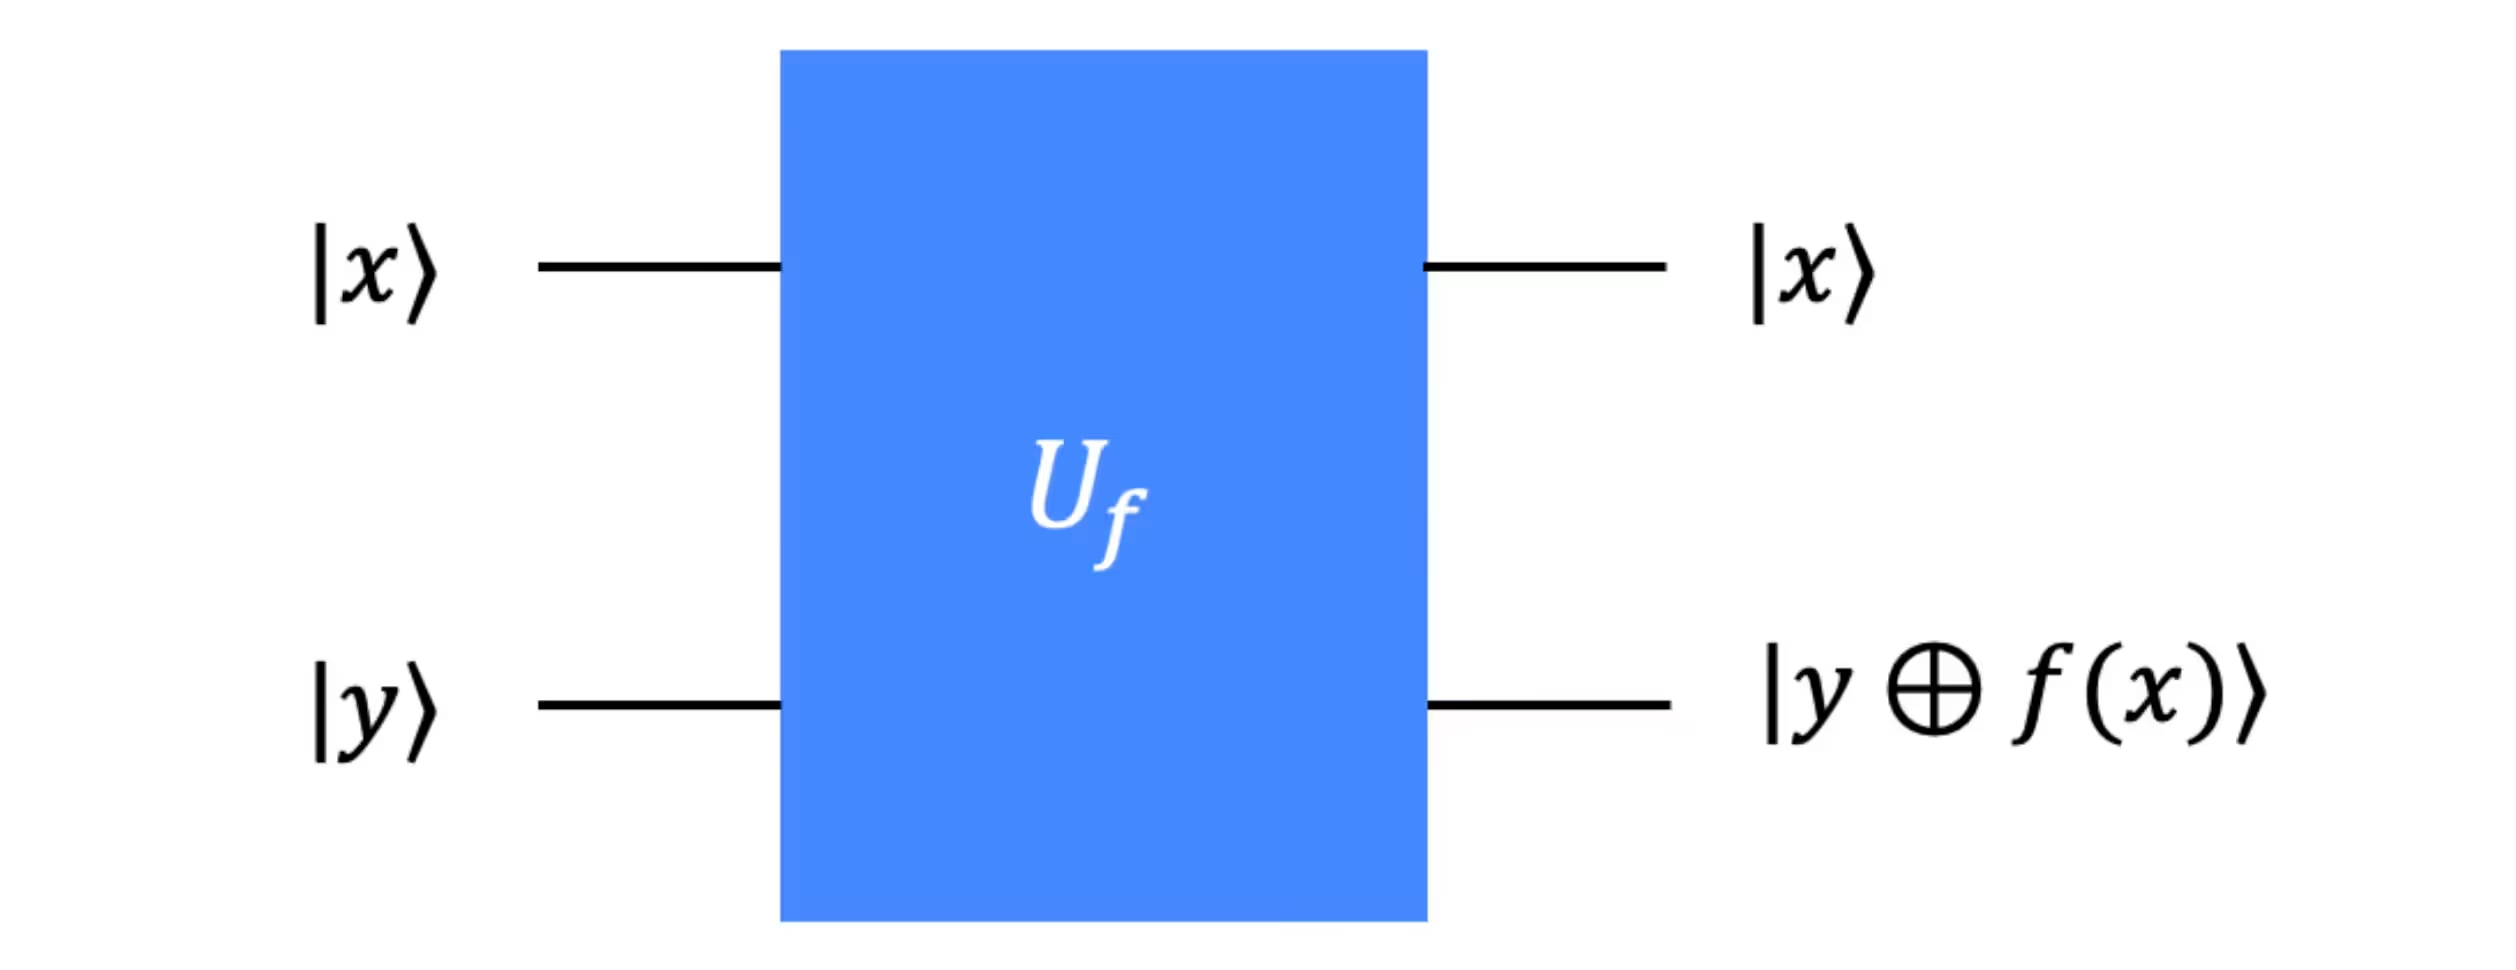
Ref: https://quantum.cloud.ibm.com/learning/en/modules/computer-science/deutsch-jozsa

### 3.a. Oracle Builder

- Constant oracle: always returns 0 (do nothing) or always returns 1 (flip output qubit).  
- Balanced oracle: output = XOR of some subset of the input bits.

We'll generate an oracle gate for n input qubits + 1 output qubit.

#### For python syntax brushup: https://www.w3schools.com/python/

In [ ]:
def make_dj_oracle(n, balanced=True, flip_constant=False):
    """Return a Deutsch-Jozsa oracle as a Gate.

    n: number of input qubits
    balanced:
        True  -> balanced function
        False -> constant function
    flip_constant:
        If constant and flip_constant=True, oracle outputs 1 for all inputs.
        Otherwise outputs 0 for all inputs.
    """

    if balanced:
        qc_oracle = QuantumCircuit(n+1)
        # Balanced oracle: CNOT from each input qubit to the output qubit
        for i in range(n):
            qc_oracle.cx(i, n)
    else:
        qc_oracle = QuantumCircuit(n+1)
        # Constant oracle: either do nothing (all 0) or flip output (all 1)
        if flip_constant:
            qc_oracle.x(n)

    return qc_oracle.to_gate(label="U balanced" if balanced else "U constant")

### 3.b. Deutsch–Jozsa Circuit Construction

Algorithm steps:
1. Initialize n input qubits in |0⟩ and one output qubit in |1⟩  
2. Apply Hadamard to all qubits  
3. Apply the oracle \(U_f\)  
4. Apply Hadamard to the first n qubits again  
5. Measure the first n qubits

**Rule:**  
- If all measured bits = 0...0 → function is **constant**  
- Otherwise → function is **balanced**

In [ ]:
def deutsch_jozsa_circuit(n, oracle_gate):
    qc = QuantumCircuit(n+1, n)

    # Step 1: prepare |0...0⟩|1⟩
    qc.x(n)

    # Step 2: Hadamard on all qubits
    qc.h(range(n+1))

    # Step 3: apply oracle
    qc.append(oracle_gate, range(n+1))

    # Step 4: Hadamard on input register only
    qc.h(range(n))

    # Step 5: measure input qubits
    qc.measure(range(n), range(n))
    return qc

n = 3  # number of input qubits
oracle_balanced = make_dj_oracle(n, balanced=True)
oracle_constant = make_dj_oracle(n, balanced=False, flip_constant=False)

qc_dj_bal = deutsch_jozsa_circuit(n, oracle_balanced)
qc_dj_const = deutsch_jozsa_circuit(n, oracle_constant)

print("Balanced oracle circuit:")
display(qc_dj_bal.draw('mpl'))

print("Constant oracle circuit:")
display(qc_dj_const.draw('mpl'))

In [ ]:
print("Balanced oracle circuit:")
display(qc_dj_bal.decompose().draw('mpl'))

print("Constant oracle circuit:")
display(qc_dj_const.decompose().draw('mpl'))

### 3.c. Run the Deutsch–Jozsa Algorithm
We'll run both versions and compare the measurement results.

In [ ]:
def run_and_get_counts(qc):
    backend = AerSimulator()
    pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
    isa_bell = pm.run(qc)

    sampler = Sampler(mode=backend)

    job = sampler.run([isa_bell], shots = 1024)
    result = job.result()
    counts = result[0].data.c.get_counts()
    return counts

counts_bal = run_and_get_counts(qc_dj_bal)
counts_con = run_and_get_counts(qc_dj_const)


print("Balanced oracle measurement counts:", counts_bal)
print("Constant oracle measurement counts:", counts_con)

In [ ]:
plot_histogram(counts_bal, title="Balanced Oracle Result")

In [ ]:
plot_histogram(counts_con, title="Constant Oracle Result")


# Part 4: Primitives, OpenQASM, and Real Hardware

## Quantum Primitives (Sampler and Estimator)

**Explanation:** Primitives are high-level interfaces for common quantum tasks.

The **Sampler** and **Estimator** are two key primitives that each serve different purposes when working with quantum circuits. They abstract away the details of execution and error mitigation, making it easier to extract meaningful information from quantum computations.

The `Estimator` computes expectation values ⟨ψ|O|ψ⟩. Here you'll initialize an `Estimator` with a backend mode, transpile your circuit using `generate_preset_pass_manager`, apply the observable to the circuit layout, then use the `.run([(circuit, observable)])` method. The result object contains expectation values accessible via `data.evs`.

In [ ]:
from qiskit.quantum_info import SparsePauliOp

bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)

observable = SparsePauliOp('ZZ')

backend = AerSimulator()
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_bell = pm.run(bell)

isa_observable = observable.apply_layout(isa_bell.layout)

estimator = Estimator(mode=backend)

job = estimator.run([(isa_bell, isa_observable)])
result = job.result()

pub_result = result[0]
exp_val = pub_result.data.evs
print(f'Expectation value for ZZ: {exp_val}')

## OpenQASM: A Quantum Assembly Language

The OpenQASM 3 string below to create a Bell state between `q[0]` and `q[1]`

```
OPENQASM 3.0;
include "stdgates.inc";
qubit[2] q;
bit[2] c;

h q[0];
cx q[0], q[1];

c = measure q;

```

In [ ]:
from qiskit import qasm3

qasm3_string_for_import = '''
OPENQASM 3.0;
include "stdgates.inc";
qubit[2] q;
bit[2] c;

h q[0];
cx q[0], q[1];

c = measure q;

'''


qc_from_qasm = qasm3.loads(qasm3_string_for_import)
qc_from_qasm.draw('mpl')

## Real Hardware

You can access real hardware using an **api key** and **crn**, follow the instructions below:

Edit the code below in the following way:
1. Comment out the following line:
```
backend = AerSimulator()
```
2. Add the following lines immediately after:
```
service = QiskitRuntimeService(name="fallfest-2025")
backend = service.least_busy(operational=True, simulator=False)
```

In [ ]:
# your_api_key = "deleteThisAndPasteYourAPIKeyHere"
# your_crn = "deleteThisAndPasteYourCRNHere"

# QiskitRuntimeService.save_account(
#     channel="ibm_quantum_platform",
#     token=your_api_key,
#     instance=your_crn,
#     name="fallfest-2026",
# )

# Check that the account has been saved properly
# print(service.saved_accounts())

bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)
bell.measure_all()


# backend = AerSimulator()

# service = QiskitRuntimeService(name="fallfest-2026")
# backend = service.least_busy(operational=True, simulator=False)

pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_bell = pm.run(bell)

sampler = Sampler(mode=backend)

job = sampler.run([isa_bell], shots=5000)
result = job.result()

counts = result[0].data.meas.get_counts()
print(f'Measurement counts: {counts}')

### More tools to look out for:
- https://quantum.cloud.ibm.com/docs/en/api/qiskit/circuit_library
- QFT: https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.QFT
- SQD: https://github.com/wagnersj/otu_qiskit_workshop_2025/blob/master/otu-qiskit-workshop-sqd.ipynb